In [20]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor


# 1. Load Data

In [3]:
df_train = pd.read_csv("deliveries_train.csv")
df_test = pd.read_csv("deliveries_test.csv")

# 2. Preprocessing & Feature Engineering

In [4]:
median_trips = df_train["courier_trips_completed"].median()
mode_weather = df_train["weather"].mode()[0]

In [5]:
def engineer_features(df):
  data = df.copy()
  data["courier_trips_completed"] = data["courier_trips_completed"].fillna(
      median_trips
  )
  data["weather"] = data["weather"].fillna(mode_weather)

  order_dt = pd.to_datetime(data["order_placed_at"])
  data["order_hour"] = order_dt.dt.hour
  data["day_of_week"] = order_dt.dt.dayofweek
  data["is_weekend"] = data["day_of_week"].isin([5, 6]).astype(int)
  data["is_peak_hour"] = data["order_hour"].isin(
      [11, 12, 13, 18, 19, 20]
  ).astype(int)

  data["subtotal_per_item"] = data["order_subtotal"] / data["items_count"].clip(
      lower=1
  )
  data["distance_prep_interaction"] = (
      data["distance_km"] * data["restaurant_avg_prep_minutes"]
  )
  return data

In [6]:
df_train_fe = engineer_features(df_train)
df_test_fe = engineer_features(df_test)

C:\Users\ADARSH K\AppData\Local\Temp\ipykernel_15928\1856173453.py:10: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  data["day_of_week"] = order_dt.dt.dayofweek
C:\Users\ADARSH K\AppData\Local\Temp\ipykernel_15928\1856173453.py:10: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  data["day_of_week"] = order_dt.dt.dayofweek


In [7]:
y = df_train_fe["delivery_minutes"]
X_raw = df_train_fe.drop(
    columns=["order_id", "order_placed_at", "delivery_minutes"]
)
X_test_raw = df_test_fe.drop(columns=["order_id", "order_placed_at"])

In [8]:
numeric_cols = [
    "restaurant_avg_prep_minutes",
    "distance_km",
    "items_count",
    "order_subtotal",
    "courier_trips_completed",
    "order_hour",
    "day_of_week",
    "subtotal_per_item",
    "distance_prep_interaction",
]
categorical_cols = ["cuisine", "city_zone", "courier_vehicle", "weather"]

# One hot Encoding

In [9]:
X_encoded = pd.get_dummies(X_raw, columns=categorical_cols, drop_first=True)
X_test_encoded = pd.get_dummies(
    X_test_raw, columns=categorical_cols, drop_first=True
)
X_test_encoded = X_test_encoded.reindex(columns=X_encoded.columns, fill_value=0)

In [10]:
X_train, X_val, y_train, y_val = train_test_split(
    X_encoded, y, test_size=0.20, random_state=42
)


In [11]:
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_val_scaled = X_val.copy()
X_test_scaled = X_test_encoded.copy()

X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_val_scaled[numeric_cols] = scaler.transform(X_val[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test_scaled[numeric_cols])

# 3. Define Model Grids for GridSearchCV

In [12]:
model_grids = {
    "Linear Regression": {
        "model": LinearRegression(),
        "params": {"fit_intercept": [True, False]},
    },
    "Ridge Regression": {
        "model": Ridge(random_state=42),
        "params": {"alpha": [0.1, 1.0, 5.0, 10.0, 20.0]},
    },
    "Random Forest": {
        "model": RandomForestRegressor(
            criterion="absolute_error", random_state=42, n_jobs=-1
        ),
        "params": {
            "n_estimators": [50, 100],
            "max_depth": [6, 10],
            "min_samples_split": [2, 5],
        },
    },
    "Gradient Boosting": {
        "model": GradientBoostingRegressor(loss="huber", random_state=42),
        "params": {
            "n_estimators": [100, 150],
            "learning_rate": [0.05, 0.1],
            "max_depth": [3, 4],
        },
    },
    "XGBoost Regressor": {
        "model": XGBRegressor(
            objective="reg:absoluteerror",  # Robust to extreme delivery outliers
            random_state=42,
            n_jobs=-1,
        ),
        "params": {
            "n_estimators": [100, 150],
            "learning_rate": [0.05, 0.1],
            "max_depth": [3, 4],
        },
    },
}

# 4. Run GridSearchCV Across All 5 Models

In [13]:
results = {}

print("Running GridSearchCV for each model (evaluating on MAE)...\n")

for name, config in model_grids.items():
  print(f"--> Tuning {name}...")
  grid_search = GridSearchCV(
      estimator=config["model"],
      param_grid=config["params"],
      scoring="neg_mean_absolute_error",
      cv=3,
      n_jobs=-1,
  )
  grid_search.fit(X_train_scaled, y_train)

Running GridSearchCV for each model (evaluating on MAE)...

--> Tuning Linear Regression...
--> Tuning Ridge Regression...
--> Tuning Random Forest...
--> Tuning Gradient Boosting...
--> Tuning XGBoost Regressor...


In [14]:
best_estimator = grid_search.best_estimator_
preds = best_estimator.predict(X_val_scaled)

In [15]:
  mae = mean_absolute_error(y_val, preds)
  rmse = np.sqrt(mean_squared_error(y_val, preds))
  r2 = r2_score(y_val, preds)

In [16]:
  results[name] = {
      "model": best_estimator,
      "best_params": grid_search.best_params_,
      "MAE": mae,
      "RMSE": rmse,
      "R2": r2,
  }

  print(f"    Best Params: {grid_search.best_params_}")
  print(f"    Val MAE: {mae:.2f} mins | RMSE: {rmse:.2f} mins | R2: {r2:.4f}\n")

    Best Params: {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 150}
    Val MAE: 3.10 mins | RMSE: 6.59 mins | R2: 0.6137



# Pick overall best model

In [17]:
best_model_name = min(results, key=lambda k: results[k]["MAE"])
best_model = results[best_model_name]["model"]

In [18]:
print(
    f"🏆 Selected Best Model: {best_model_name} with Validation MAE:"
    f" {results[best_model_name]['MAE']:.2f} mins"
)

🏆 Selected Best Model: XGBoost Regressor with Validation MAE: 3.10 mins


# Generate & Save '2_model_comparison.png'

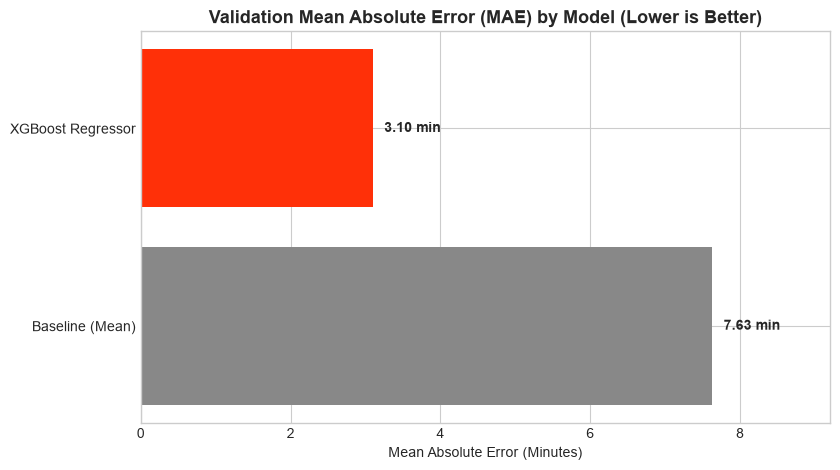

In [29]:
plt.style.use("seaborn-v0_8-whitegrid")

# --- Graph 1: Validation MAE Comparison ---
baseline_mae = mean_absolute_error(y_val, np.full(len(y_val), y_train.mean()))
maes = {"Baseline (Mean)": baseline_mae}
for name, info in results.items():
  maes[name] = info["MAE"]

sorted_models = sorted(maes.items(), key=lambda x: x[1], reverse=True)
names = [x[0] for x in sorted_models]
scores = [x[1] for x in sorted_models]
colors = [
    "#888888"
    if n == "Baseline (Mean)"
    else ("#FF3008" if n == best_model_name else "#4A90E2")
    for n in names
]

fig, ax = plt.subplots(figsize=(8.5, 4.8))
bars = ax.barh(names, scores, color=colors)

ax.set_title(
    "Validation Mean Absolute Error (MAE) by Model (Lower is Better)",
    fontsize=13,
    fontweight="bold",
)
ax.set_xlabel("Mean Absolute Error (Minutes)")

for bar in bars:
  width = bar.get_width()
  ax.text(
      width + 0.15,
      bar.get_y() + bar.get_height() / 2,
      f"{width:.2f} min",
      va="center",
      fontweight="bold",
  )

ax.set_xlim(0, 9.2)
plt.tight_layout()
plt.savefig("2_model_comparison.png", dpi=200)
plt.show()

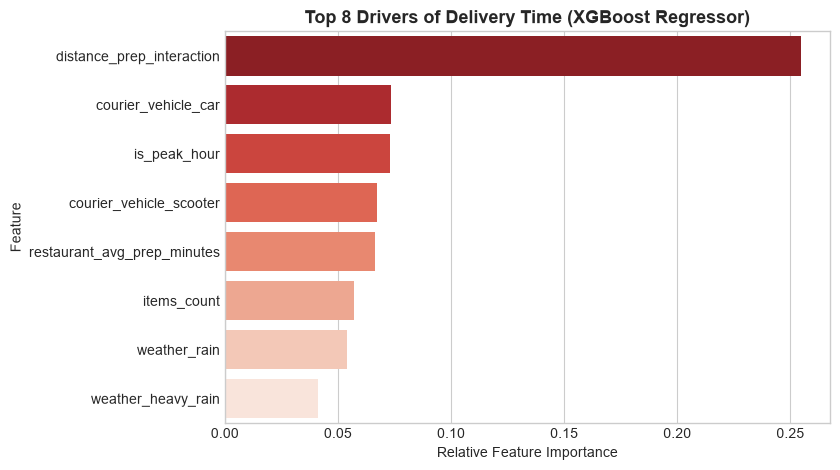

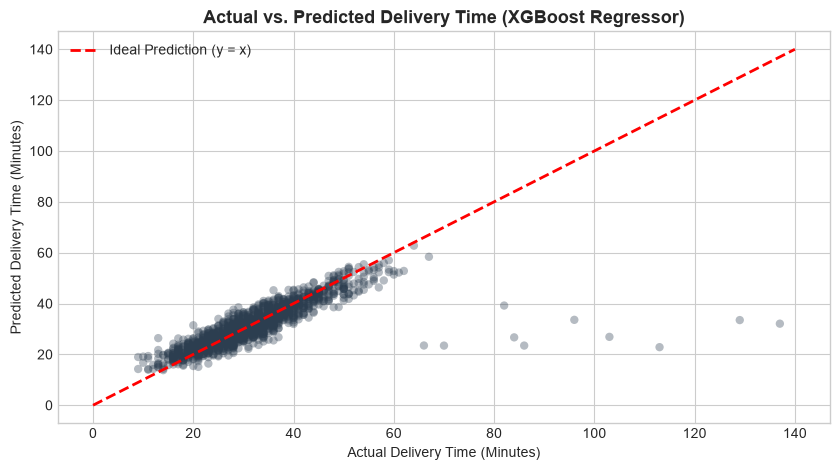

Done! Saved 2_model_comparison.png, 3_feature_importance.png, and 4_actual_vs_predicted.png.


In [30]:
importances = pd.Series(
    best_model.feature_importances_, index=X_encoded.columns
).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8.5, 4.8))
top_feats = importances.head(8)
sns.barplot(
    x=top_feats.values,
    y=top_feats.index,
    hue=top_feats.index,
    palette="Reds_r",
    legend=False,
    ax=ax,
)
ax.set_title(
    f"Top 8 Drivers of Delivery Time ({best_model_name})",
    fontsize=13,
    fontweight="bold",
)
ax.set_xlabel("Relative Feature Importance")
ax.set_ylabel("Feature")
plt.tight_layout()
plt.savefig("3_feature_importance.png", dpi=200)
plt.show()

# --- Graph 3: Actual vs. Predicted Delivery Time ---
val_preds = best_model.predict(X_val_scaled)

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.scatter(y_val, val_preds, alpha=0.35, color="#2C3E50", edgecolors="none")
ax.plot([0, 140], [0, 140], "r--", lw=2, label="Ideal Prediction (y = x)")
ax.set_title(
    f"Actual vs. Predicted Delivery Time ({best_model_name})",
    fontsize=13,
    fontweight="bold",
)
ax.set_xlabel("Actual Delivery Time (Minutes)")
ax.set_ylabel("Predicted Delivery Time (Minutes)")
ax.legend()
plt.tight_layout()
plt.savefig("4_actual_vs_predicted.png", dpi=200)
plt.show()

print(
    "Done! Saved 2_model_comparison.png, 3_feature_importance.png, and"
    " 4_actual_vs_predicted.png."
)

# 5. Predict on Test Set & Save Artifacts

In [31]:
final_preds = best_model.predict(X_test_scaled)
pd.DataFrame({
    "order_id": df_test["order_id"],
    "predicted_minutes": np.round(final_preds, 2),
}).to_csv("predictions.csv", index=False)

bundle = {
    "models": {k: v["model"] for k, v in results.items()},
    "metrics": {
        k: {"MAE": v["MAE"], "RMSE": v["RMSE"], "R2": v["R2"]}
        for k, v in results.items()
    },
    "best_model_name": best_model_name,
    "feature_columns": list(X_encoded.columns),
    "numeric_cols": numeric_cols,
    "scaler": scaler,
    "median_trips": median_trips,
    "mode_weather": mode_weather,
}

In [32]:
with open("models_dict.pkl", "wb") as f:
  pickle.dump(bundle, f)

print("Saved 'predictions.csv' and 'models_dict.pkl' successfully.")

Saved 'predictions.csv' and 'models_dict.pkl' successfully.
